In [12]:
import pandas as pd
from pathlib import Path
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("houseprice_data.csv")

In [4]:
df

,Property_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location_Score,School_Score,Current_Price,Price_Year_1,Price_Year_2,Price_Year_3,Price_Year_4,Price_After_5_Years,Price_Category
0,1,2751,3,4,3,1989,54,58,624636,656833,690689,726290,763726,803092,Medium
1,2,3322,5,1,1,2019,62,78,694237,729166,765853,804385,844856,887363,Medium
2,3,4765,3,3,2,1989,57,50,771778,803688,836917,871520,907554,945078,Medium
3,4,4512,2,2,3,2004,57,90,792597,854577,921404,993457,1071144,1154906,High
4,5,2436,3,1,1,1987,76,69,580257,612034,645552,680905,718194,757525,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,1563,5,1,2,2018,72,69,487618,516856,547847,580696,615515,652422,Low
496,497,4682,4,1,2,1982,69,96,934003,997429,1065162,1137495,1214740,1297231,High
497,498,4205,3,4,1,1989,96,52,821328,855209,890488,927222,965472,1005300,Medium
498,499,3413,5,2,1,1998,96,63,746551,806353,870945,940712,1016067,1097459,High


In [6]:

df.shape

(500, 15)

In [7]:
df.columns.tolist()

['Property_ID',
 'Area_sqft',
 'Bedrooms',
 'Bathrooms',
 'Floors',
 'Year_Built',
 'Location_Score',
 'School_Score',
 'Current_Price',
 'Price_Year_1',
 'Price_Year_2',
 'Price_Year_3',
 'Price_Year_4',
 'Price_After_5_Years',
 'Price_Category']

In [8]:
df.dtypes.to_string()

'Property_ID            int64\nArea_sqft              int64\nBedrooms               int64\nBathrooms              int64\nFloors                 int64\nYear_Built             int64\nLocation_Score         int64\nSchool_Score           int64\nCurrent_Price          int64\nPrice_Year_1           int64\nPrice_Year_2           int64\nPrice_Year_3           int64\nPrice_Year_4           int64\nPrice_After_5_Years    int64\nPrice_Category           str'

In [ ]:
df.isna().sum().to_string()  #mssng values 

'Property_ID            0\nArea_sqft              0\nBedrooms               0\nBathrooms              0\nFloors                 0\nYear_Built             0\nLocation_Score         0\nSchool_Score           0\nCurrent_Price          0\nPrice_Year_1           0\nPrice_Year_2           0\nPrice_Year_3           0\nPrice_Year_4           0\nPrice_After_5_Years    0\nPrice_Category         0'

In [10]:
df.duplicated().sum() # duplcate value

np.int64(0)

In [11]:
df.describe(include="all").transpose().to_string()  # summary

'                     count unique   top freq        mean            std       min        25%       50%        75%        max\nProperty_ID          500.0    NaN   NaN  NaN       250.5     144.481833       1.0     125.75     250.5     375.25      500.0\nArea_sqft            500.0    NaN   NaN  NaN    2979.942    1198.840073     802.0    1956.25    2999.5     4027.5     4973.0\nBedrooms             500.0    NaN   NaN  NaN       3.022       1.414751       1.0        2.0       3.0        4.0        5.0\nBathrooms            500.0    NaN   NaN  NaN       2.502         1.1011       1.0        2.0       3.0        3.0        4.0\nFloors               500.0    NaN   NaN  NaN       1.878       0.822477       1.0        1.0       2.0        3.0        3.0\nYear_Built           500.0    NaN   NaN  NaN    2000.856      12.905051    1980.0     1989.0    2001.0     2012.0     2023.0\nLocation_Score       500.0    NaN   NaN  NaN      75.138       14.60471      50.0       62.0      75.5       88.0    

In [13]:
df['Price_Category'] = df['Price_Category'].str.strip().str.title()

print(df.dtypes)

Property_ID            int64
Area_sqft              int64
Bedrooms               int64
Bathrooms              int64
Floors                 int64
Year_Built             int64
Location_Score         int64
School_Score           int64
Current_Price          int64
Price_Year_1           int64
Price_Year_2           int64
Price_Year_3           int64
Price_Year_4           int64
Price_After_5_Years    int64
Price_Category           str
dtype: object


In [14]:
print(df['Price_Category'].value_counts())

Price_Category
High      170
Medium    165
Low       165
Name: count, dtype: int64


In [15]:
current_year = 2026

df['Property_Age'] = current_year - df['Year_Built']

In [16]:
df['Price_Per_Sqft'] = df['Current_Price'] / df['Area_sqft']

In [17]:
df['Appreciation_Rate'] = (
    (df['Price_After_5_Years'] - df['Current_Price'])
    / df['Current_Price']
) * 100

In [18]:
df[['Property_Age', 'Price_Per_Sqft', 'Appreciation_Rate']].head()

,Property_Age,Price_Per_Sqft,Appreciation_Rate
0,37,227.057797,28.569599
1,7,208.981638,27.818454
2,37,161.968101,22.454644
3,22,175.664229,45.711629
4,39,238.200739,30.549912


In [19]:
investment_threshold = df['Appreciation_Rate'].median()

print("Investment Threshold:", investment_threshold)

Investment Threshold: 36.20975056157536


In [20]:
df['Good_Investment'] = np.where(
    df['Appreciation_Rate'] > investment_threshold,
    1,
    0
)

In [21]:
df['Investment_Label'] = df['Good_Investment'].map({
    1: 'Good Investment',
    0: 'Not Good Investment'
})

In [22]:
df['Investment_Label'].value_counts()

Investment_Label
Not Good Investment    250
Good Investment        250
Name: count, dtype: int64

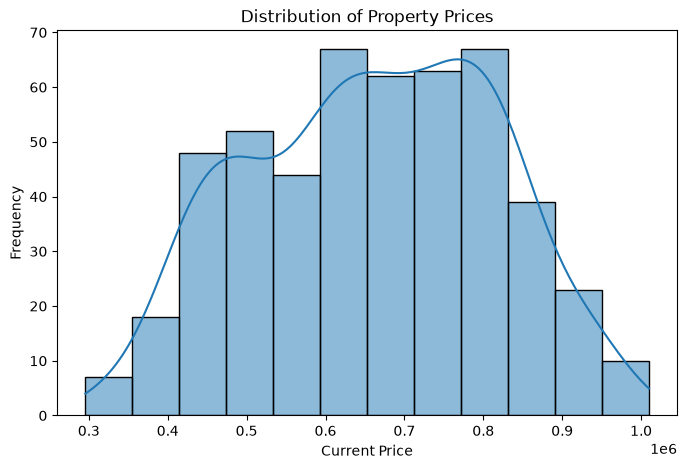

In [ ]:
# Distribution of Property Sizes
plt.figure(figsize=(8,5))

sns.histplot(df['Current_Price'], kde=True)

plt.title("Distribution of Property Sizes")
plt.xlabel("Current Price")
plt.ylabel("Frequency")

plt.show()

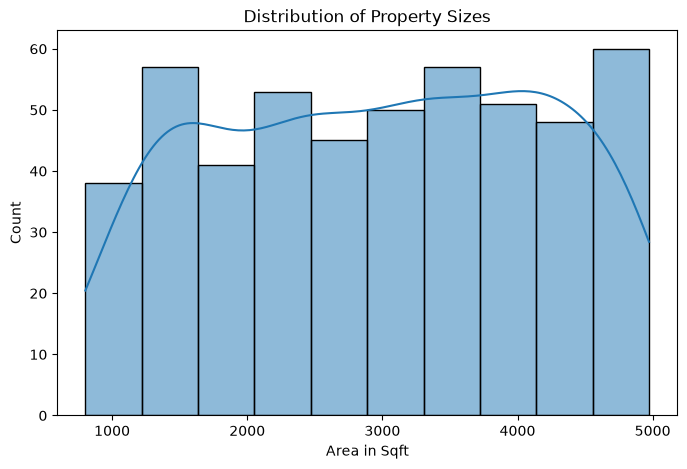

In [ ]:
# Distribution of Property Sizes
plt.figure(figsize=(8,5))

sns.histplot(df['Area_sqft'], kde=True)

plt.title("Distribution of Property Sizes")
plt.xlabel("Area in Sqft")

plt.show()

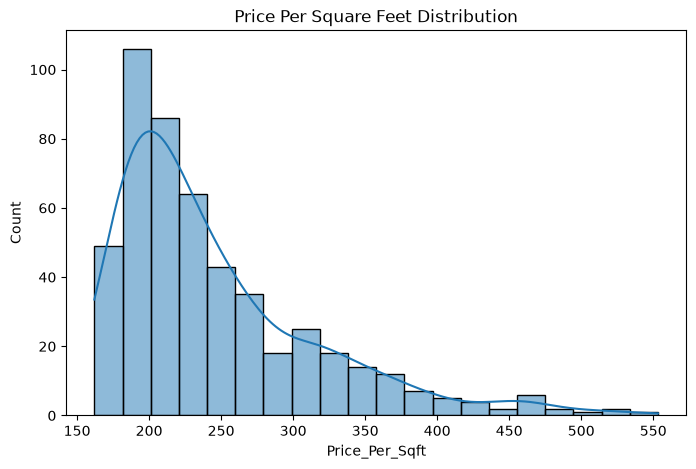

In [ ]:
# Price Per Square Feet Distribution
plt.figure(figsize=(8,5))

sns.histplot(df['Price_Per_Sqft'], kde=True)

plt.title("Price Per Square Feet Distribution")

plt.show()

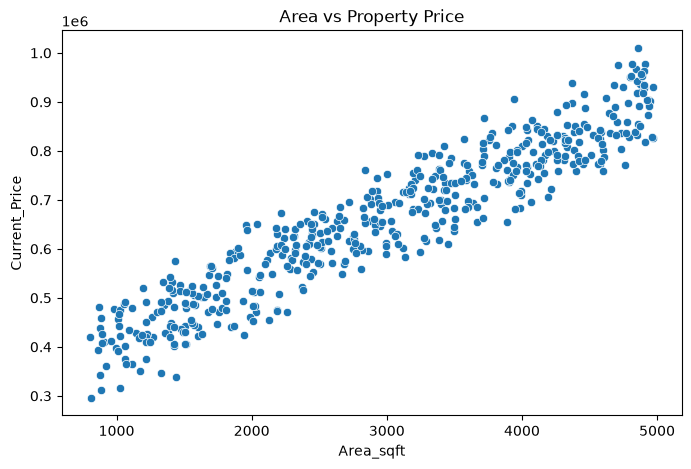

In [ ]:
#Area vs Property Price
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Area_sqft',
    y='Current_Price'
)

plt.title("Area vs Property Price")

plt.show()

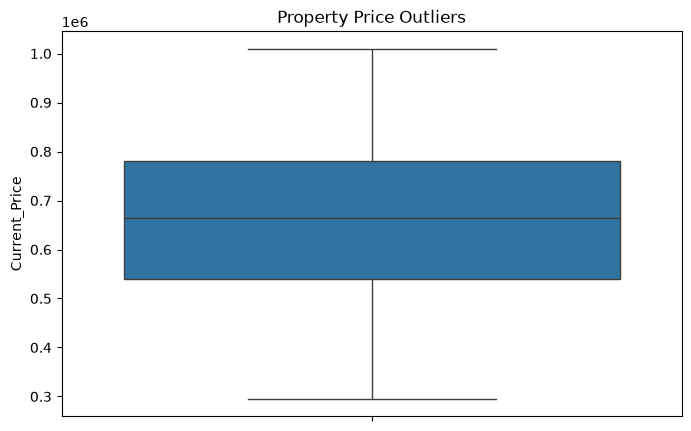

In [28]:
#Outlier Detection
plt.figure(figsize=(8,5))

sns.boxplot(y=df['Current_Price'])

plt.title("Property Price Outliers")

plt.show()

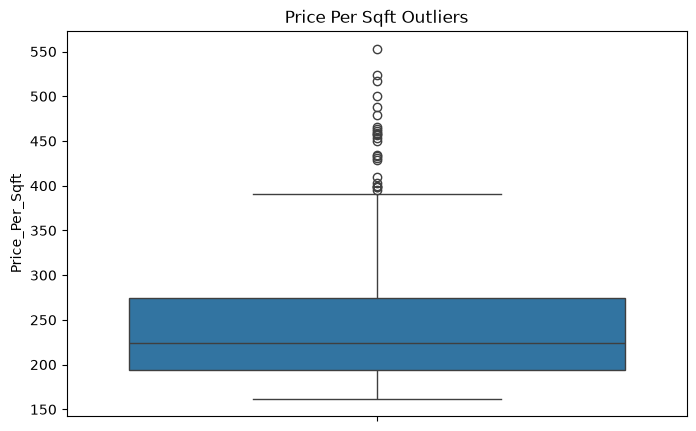

In [29]:
# Price Per Sqft Outliers
plt.figure(figsize=(8,5))

sns.boxplot(y=df['Price_Per_Sqft'])

plt.title("Price Per Sqft Outliers")

plt.show()

In [30]:
df.groupby('Location_Score')['Price_Per_Sqft'].mean().head(15)

Location_Score
50    237.965837
51    262.112120
52    251.841950
53    228.199947
54    224.769362
55    222.842459
56    248.289450
57    204.257801
58    219.901703
59    233.964529
60    263.534070
61    277.699292
62    209.904420
63    249.195611
64    224.013185
Name: Price_Per_Sqft, dtype: float64

In [31]:
print("Average Property Price:", df['Current_Price'].mean())

Average Property Price: 660302.214


In [32]:
print("Median Property Age:", df['Property_Age'].median())

Median Property Age: 25.0


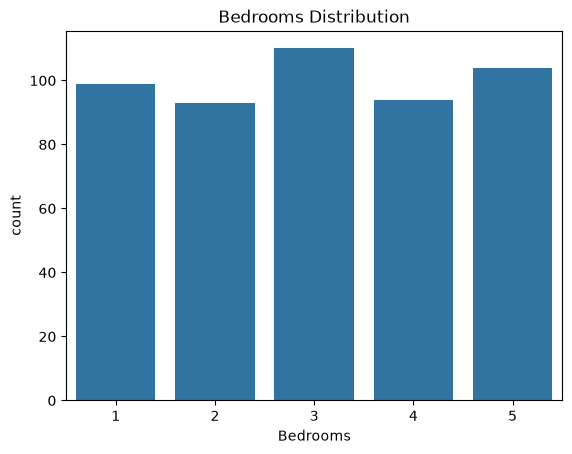

In [33]:
# Bedrooms Distribution
sns.countplot(data=df, x='Bedrooms')

plt.title("Bedrooms Distribution")

plt.show()

In [34]:
# Top 5 Expensive Properties
top_5 = df.nlargest(5, 'Current_Price')

top_5[['Property_ID', 'Current_Price', 'Area_sqft']]

,Property_ID,Current_Price,Area_sqft
392,393,1010002,4860
86,87,977724,4817
241,242,976751,4913
47,48,974558,4713
12,13,966377,4842


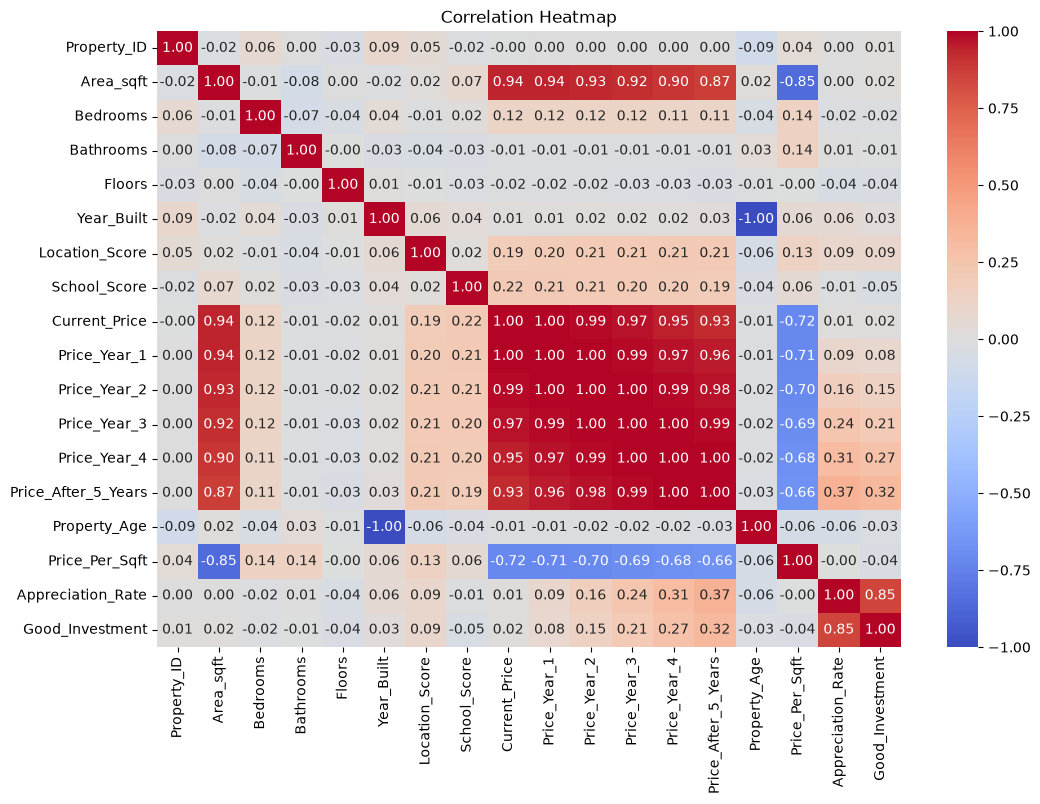

In [36]:
# Correlation Between Numerical Features
plt.figure(figsize=(12,8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

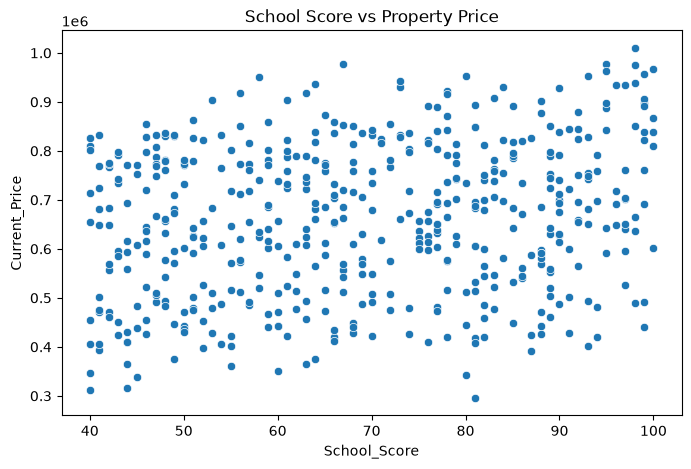

In [37]:
# Nearby Schools and Property Price

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='School_Score',
    y='Current_Price'
)

plt.title("School Score vs Property Price")

plt.show()

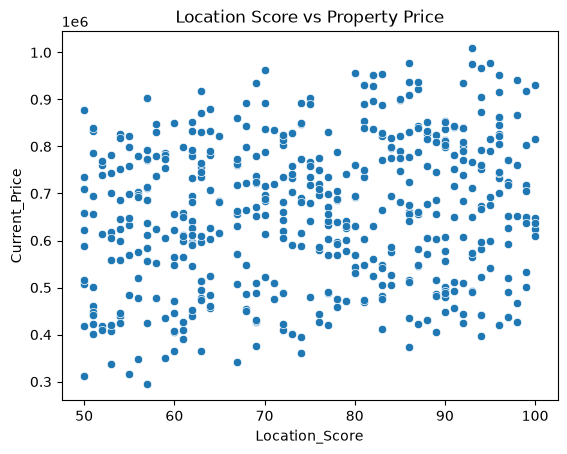

In [38]:
# Nearby Hospitals and Property Price
sns.scatterplot(
    data=df,
    x='Location_Score',
    y='Current_Price'
)

plt.title("Location Score vs Property Price")

plt.show()

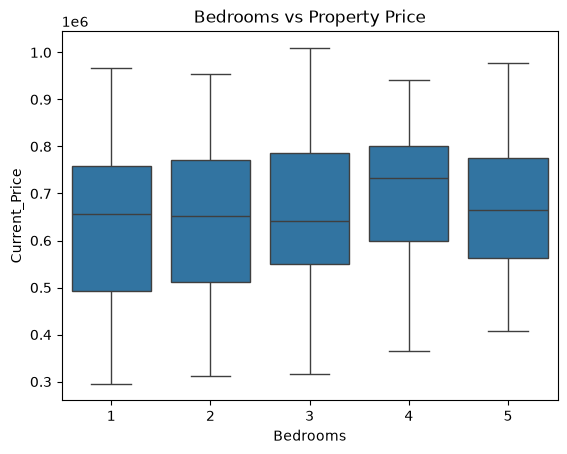

In [39]:
# Furnished Status and Price
sns.boxplot(
    data=df,
    x='Bedrooms',
    y='Current_Price'
)

plt.title("Bedrooms vs Property Price")

plt.show()

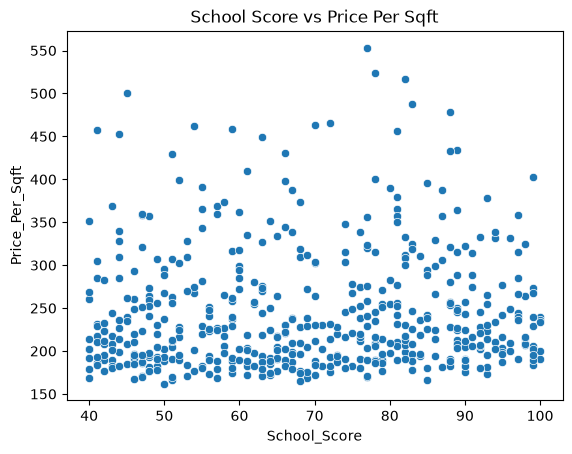

In [41]:
# Property Facing Direction
sns.scatterplot(
    data=df,
    x='School_Score',
    y='Price_Per_Sqft'
)

plt.title("School Score vs Price Per Sqft")

plt.show()

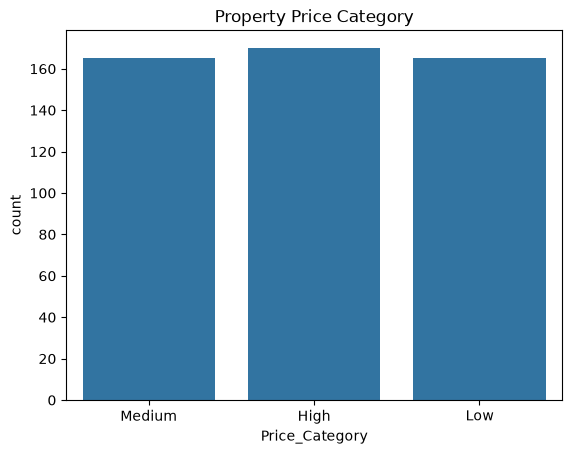

In [42]:
# Owner Type Analysis
sns.countplot(
    data=df,
    x='Price_Category'
)

plt.title("Property Price Category")

plt.show()

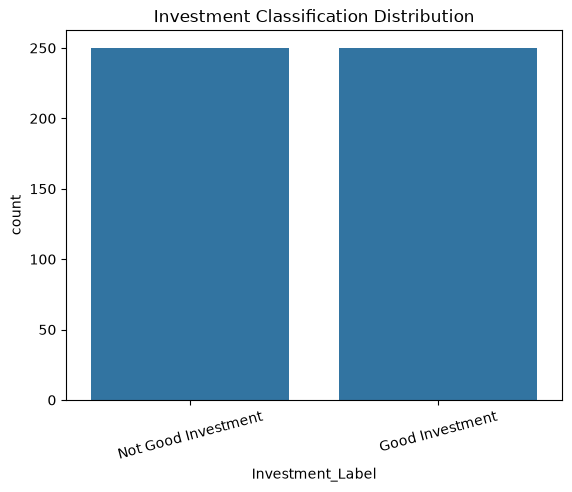

In [43]:
# Availability Status
sns.countplot(
    data=df,
    x='Investment_Label'
)

plt.title("Investment Classification Distribution")

plt.xticks(rotation=15)

plt.show()

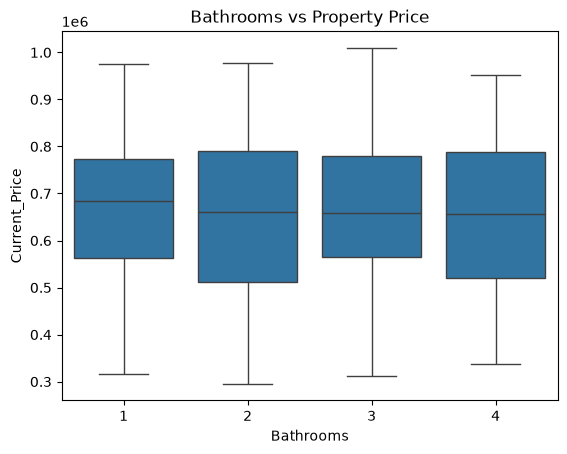

In [44]:
# Parking Space and Property Price
sns.boxplot(
    data=df,
    x='Bathrooms',
    y='Current_Price'
)

plt.title("Bathrooms vs Property Price")

plt.show()

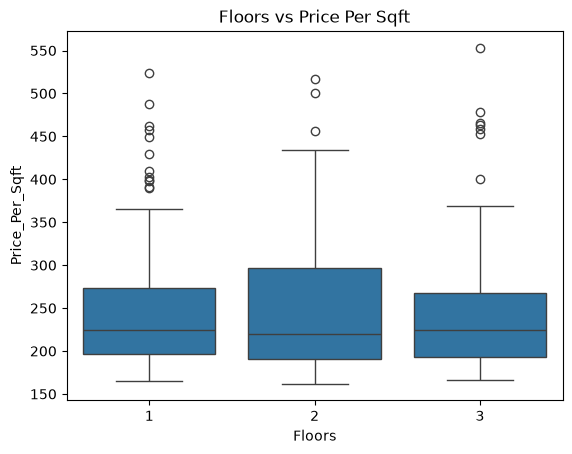

In [45]:
# Amenities and Price Per Sqft
sns.boxplot(
    data=df,
    x='Floors',
    y='Price_Per_Sqft'
)

plt.title("Floors vs Price Per Sqft")

plt.show()

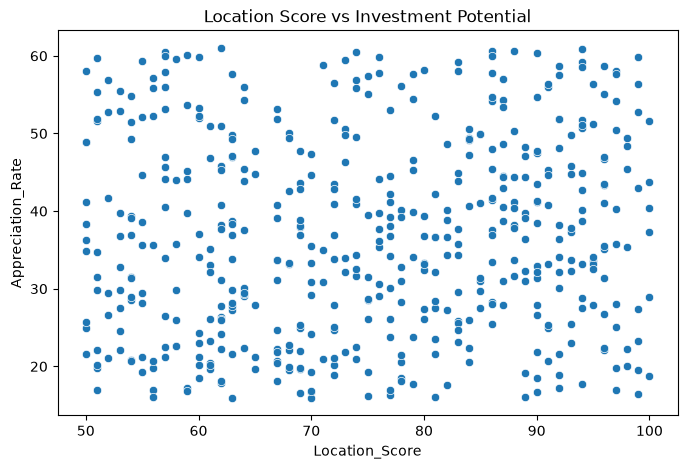

In [46]:
# Public Transport Accessibility
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Location_Score',
    y='Appreciation_Rate'
)

plt.title("Location Score vs Investment Potential")

plt.show()

Classification

In [47]:
# Prepare Features and Target
features = [
    'Area_sqft',
    'Bedrooms',
    'Bathrooms',
    'Floors',
    'Property_Age',
    'Location_Score',
    'School_Score',
    'Current_Price',
    'Price_Per_Sqft'
]

X = df[features]

y = df['Good_Investment']

print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

Features Shape: (500, 9)
Target Shape: (500,)


In [48]:
# Train Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (400, 9)
Testing Data: (100, 9)


In [49]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [56]:
# Import Classification Models
from xgboost import XGBClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

print("Classification Models Imported")

Classification Models Imported


In [51]:
# Train Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

lr_prediction = lr_model.predict(X_test_scaled)

In [52]:
# Train Decision Tree
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_prediction = dt_model.predict(X_test)

In [53]:
# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_prediction = rf_model.predict(X_test)

In [58]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)
xgb_prediction = xgb_model.predict(X_test)

In [59]:
# Model Evaluation
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, lr_prediction)

dt_accuracy = accuracy_score(y_test, dt_prediction)

rf_accuracy = accuracy_score(y_test, rf_prediction)

xgb_accuracy = accuracy_score(
    y_test,
    xgb_prediction
)

print("XGBoost Accuracy:", xgb_accuracy)


print("Logistic Regression:", lr_accuracy)

print("Decision Tree:", dt_accuracy)

print("Random Forest:", rf_accuracy)

XGBoost Accuracy: 0.58
Logistic Regression: 0.57
Decision Tree: 0.59
Random Forest: 0.52


In [60]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        xgb_prediction,
        target_names=[
            'Not Good Investment',
            'Good Investment'
        ]
    )
)

                     precision    recall  f1-score   support

Not Good Investment       0.57      0.68      0.62        50
    Good Investment       0.60      0.48      0.53        50

           accuracy                           0.58       100
          macro avg       0.58      0.58      0.58       100
       weighted avg       0.58      0.58      0.58       100



In [55]:
# Classification Report
from sklearn.metrics import classification_report

print("Random Forest Classification Report")

print(
    classification_report(
        y_test,
        rf_prediction,
        target_names=[
            'Not Good Investment',
            'Good Investment'
        ]
    )
)

Random Forest Classification Report
                     precision    recall  f1-score   support

Not Good Investment       0.52      0.64      0.57        50
    Good Investment       0.53      0.40      0.45        50

           accuracy                           0.52       100
          macro avg       0.52      0.52      0.51       100
       weighted avg       0.52      0.52      0.51       100



In [61]:
classification_results = pd.DataFrame({

    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],

    'Accuracy': [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        xgb_accuracy
    ]
})

classification_results = classification_results.sort_values(
    by='Accuracy',
    ascending=False
)

print(classification_results)

                 Model  Accuracy
1        Decision Tree      0.59
3              XGBoost      0.58
0  Logistic Regression      0.57
2        Random Forest      0.52


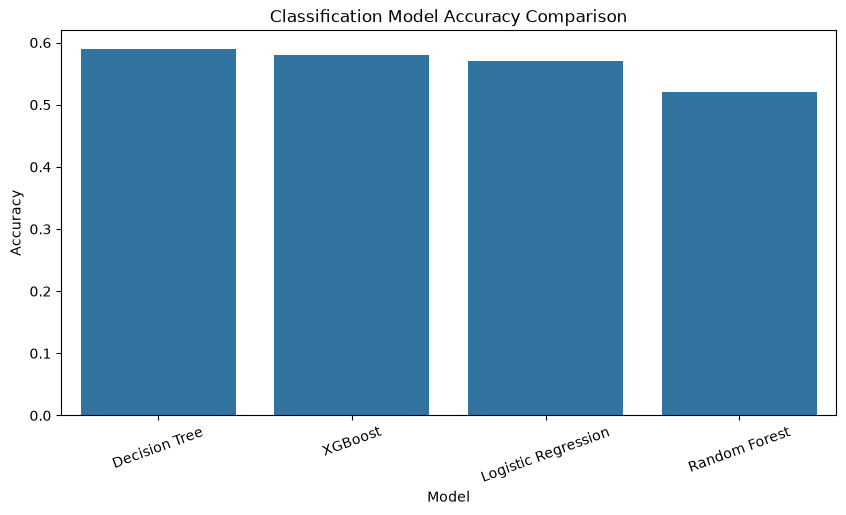

In [62]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=classification_results,
    x='Model',
    y='Accuracy'
)

plt.title("Classification Model Accuracy Comparison")

plt.ylabel("Accuracy")

plt.xticks(rotation=20)

plt.show()

In [63]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, classification_report

# Extra Trees Model
et_model = ExtraTreesClassifier(
    random_state=42,
    class_weight="balanced"
)

# Parameters for tuning
param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

# Hyperparameter Tuning
et_grid = RandomizedSearchCV(
    estimator=et_model,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

# Train model
et_grid.fit(X_train, y_train)

# Best model
best_et_model = et_grid.best_estimator_

# Prediction
et_prediction = best_et_model.predict(X_test)

# Accuracy
et_accuracy = accuracy_score(y_test, et_prediction)

print("Best Parameters:", et_grid.best_params_)
print("Best CV Accuracy:", et_grid.best_score_)
print("Extra Trees Test Accuracy:", et_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, et_prediction))

Best Parameters: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 10}
Best CV Accuracy: 0.5225
Extra Trees Test Accuracy: 0.47

Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.56      0.51        50
           1       0.46      0.38      0.42        50

    accuracy                           0.47       100
   macro avg       0.47      0.47      0.47       100
weighted avg       0.47      0.47      0.47       100



In [64]:
# Check class distribution
print("Target Distribution:")
print(df['Good_Investment'].value_counts())

# Check correlation with target
correlation = df[[
    'Area_sqft',
    'Bedrooms',
    'Bathrooms',
    'Floors',
    'Property_Age',
    'Location_Score',
    'School_Score',
    'Current_Price',
    'Price_Per_Sqft',
    'Good_Investment'
]].corr()

print("\nCorrelation with Good_Investment:")
print(correlation['Good_Investment'].sort_values(ascending=False))

Target Distribution:
Good_Investment
0    250
1    250
Name: count, dtype: int64

Correlation with Good_Investment:
Good_Investment    1.000000
Location_Score     0.093351
Area_sqft          0.020906
Current_Price      0.015598
Bathrooms         -0.005455
Bedrooms          -0.018396
Property_Age      -0.028234
Floors            -0.036512
Price_Per_Sqft    -0.037704
School_Score      -0.046024
Name: Good_Investment, dtype: float64


In [65]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report

# Model
hgb_model = HistGradientBoostingClassifier(
    random_state=42
)

# Parameters
params = {
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_iter': [100, 200, 300],
    'max_leaf_nodes': [7, 15, 20, 31],
    'max_depth': [None, 3, 5, 7],
    'min_samples_leaf': [5, 10, 15, 20],
    'l2_regularization': [0, 0.1, 1, 5]
}

# Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Hyperparameter Tuning
hgb_grid = RandomizedSearchCV(
    hgb_model,
    param_distributions=params,
    n_iter=25,
    cv=cv,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

# Train
hgb_grid.fit(X_train, y_train)

# Best model
best_hgb_model = hgb_grid.best_estimator_

# Prediction
hgb_prediction = best_hgb_model.predict(X_test)

# Results
print("Best Parameters:", hgb_grid.best_params_)
print("Best CV Accuracy:", hgb_grid.best_score_)

print("Test Accuracy:",
      accuracy_score(y_test, hgb_prediction))

print("\nClassification Report:")
print(classification_report(y_test, hgb_prediction))

Best Parameters: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 300, 'max_depth': 5, 'learning_rate': 0.03, 'l2_regularization': 0.1}
Best CV Accuracy: 0.515
Test Accuracy: 0.5

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.54      0.52        50
           1       0.50      0.46      0.48        50

    accuracy                           0.50       100
   macro avg       0.50      0.50      0.50       100
weighted avg       0.50      0.50      0.50       100



In [66]:
# Check actual appreciation
print("Appreciation Statistics:")
print(df['Appreciation_Rate'].describe())

# Check target with actual future price
print("\nInvestment Category Analysis:")

print(
    df.groupby('Good_Investment')[
        ['Current_Price', 'Price_After_5_Years', 'Appreciation_Rate']
    ].mean()
)

# Check first 10 records
display(
    df[[
        'Current_Price',
        'Price_After_5_Years',
        'Appreciation_Rate',
        'Good_Investment'
    ]].head(10)
)

Appreciation Statistics:
count    500.000000
mean      36.802423
std       12.591448
min       15.926863
25%       26.107507
50%       36.209751
75%       46.949225
max       61.010034
Name: Appreciation_Rate, dtype: float64

Investment Category Analysis:
                 Current_Price  Price_After_5_Years  Appreciation_Rate
Good_Investment                                                       
0                   657895.952           829915.988          26.109515
1                   662708.476           977137.156          47.495331


,Current_Price,Price_After_5_Years,Appreciation_Rate,Good_Investment
0,624636,803092,28.569599,0
1,694237,887363,27.818454,0
2,771778,945078,22.454644,0
3,792597,1154906,45.711629,1
4,580257,757525,30.549912,0
5,657767,829179,26.059684,0
6,829908,1055634,27.198918,0
7,898322,1176484,30.964621,0
8,771315,1051674,36.348185,1
9,692540,885651,27.884454,0


In [67]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Input Features
reg_features = [
    'Area_sqft',
    'Bedrooms',
    'Bathrooms',
    'Floors',
    'Property_Age',
    'Location_Score',
    'School_Score',
    'Current_Price'
]

X_reg = df[reg_features]

# Target
y_reg = df['Price_After_5_Years']

# Train Test Split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

# Model
rf_reg_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

# Training
rf_reg_model.fit(X_train_reg, y_train_reg)

# Prediction
reg_prediction = rf_reg_model.predict(X_test_reg)

# Evaluation
mae = mean_absolute_error(y_test_reg, reg_prediction)

rmse = np.sqrt(
    mean_squared_error(y_test_reg, reg_prediction)
)

r2 = r2_score(y_test_reg, reg_prediction)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 79566.8185576241
RMSE: 97603.96578217838
R2 Score: 0.8202572545782774


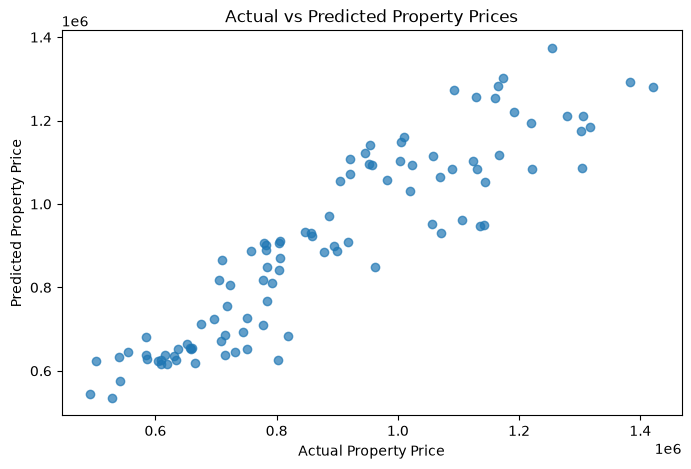

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test_reg, reg_prediction, alpha=0.7)

plt.xlabel("Actual Property Price")
plt.ylabel("Predicted Property Price")
plt.title("Actual vs Predicted Property Prices")

plt.show()

          Feature  Importance
7   Current_Price    0.912782
5  Location_Score    0.018371
0       Area_sqft    0.017468
4    Property_Age    0.016547
6    School_Score    0.015677
1        Bedrooms    0.009081
2       Bathrooms    0.005280
3          Floors    0.004793


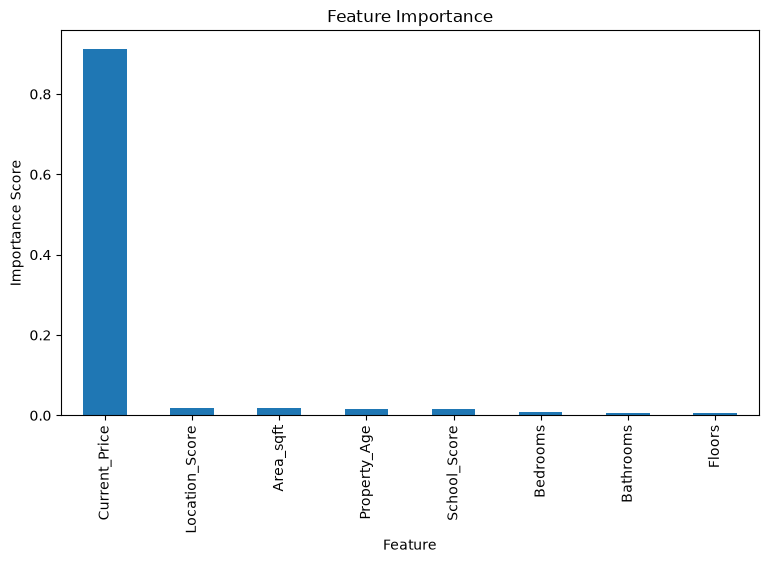

In [69]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    'Feature': reg_features,
    'Importance': rf_reg_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

importance.plot(
    x='Feature',
    y='Importance',
    kind='bar',
    legend=False,
    figsize=(9, 5)
)

plt.title("Feature Importance")
plt.ylabel("Importance Score")
plt.show()

In [70]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [71]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42
    )
}

In [72]:
results = []

for name, model in models.items():

    # Train model
    model.fit(X_train_reg, y_train_reg)

    # Make predictions
    predictions = model.predict(X_test_reg)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test_reg, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test_reg, predictions)
    )

    r2 = r2_score(y_test_reg, predictions)

    # Store results
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

In [73]:
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="R2 Score",
    ascending=False
)

print(comparison_df)

               Model           MAE           RMSE  R2 Score
0  Linear Regression  72625.249025   86609.105761  0.858472
3  Gradient Boosting  77277.200900   92867.419733  0.837279
2      Random Forest  79566.818558   97603.965782  0.820257
4        Extra Trees  80795.366250   97932.425548  0.819045
1      Decision Tree  99128.670000  125309.082885  0.703734


In [74]:
best_model_name = comparison_df.iloc[0]["Model"]

print("Best Regression Model:", best_model_name)

Best Regression Model: Linear Regression


In [75]:
# Select best model
best_model = models[best_model_name]

print("Selected Model:", best_model_name)

Selected Model: Linear Regression


In [76]:
# Make predictions
best_predictions = best_model.predict(X_test_reg)

# Display actual and predicted prices
prediction_df = pd.DataFrame({
    "Actual Price": y_test_reg.values,
    "Predicted Price": best_predictions
})

print(prediction_df.head(10))

   Actual Price  Predicted Price
0       1192313     1.167018e+06
1        920699     1.069997e+06
2        751815     7.604612e+05
3        631125     6.833703e+05
4       1130082     1.009773e+06
5       1164528     1.178013e+06
6        608714     6.471141e+05
7        957565     1.066983e+06
8       1304552     1.111629e+06
9        805757     9.231307e+05


In [77]:
import joblib

joblib.dump(
    best_model,
    "best_regression_model.joblib"
)

print("Best Regression Model Saved Successfully!")

Best Regression Model Saved Successfully!


In [78]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import joblib

In [79]:
best_classification_model = Pipeline([
    ("scaler", StandardScaler()),

    ("classifier", LogisticRegression(
        C=10,
        penalty="l2",
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

In [80]:
best_classification_model.fit(X_train, y_train)

print("Classification Model Trained Successfully!")

Classification Model Trained Successfully!


c:\Users\annu3\OneDrive\Desktop\HousePrice\house\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [81]:
from sklearn.metrics import accuracy_score, classification_report

classification_predictions = best_classification_model.predict(X_test)

accuracy = accuracy_score(y_test, classification_predictions)

print("Classification Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, classification_predictions))

Classification Accuracy: 56.99999999999999 %

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.54      0.56        50
           1       0.57      0.60      0.58        50

    accuracy                           0.57       100
   macro avg       0.57      0.57      0.57       100
weighted avg       0.57      0.57      0.57       100



In [82]:
joblib.dump(
    best_classification_model,
    "best_classification_model.joblib"
)

print("Best Classification Model Saved Successfully!")

Best Classification Model Saved Successfully!


In [83]:
import os

print("Saved Model Files:")

for file in [
    "best_classification_model.joblib",
    "best_regression_model.joblib"
]:
    if os.path.exists(file):
        print(file, "- Saved Successfully")
    else:
        print(file, "- Not Found")

Saved Model Files:
best_classification_model.joblib - Saved Successfully
best_regression_model.joblib - Saved Successfully


In [84]:
import mlflow
import mlflow.sklearn

mlflow.set_experiment("Real Estate Investment Advisor")

print("MLflow Experiment Created Successfully!")

2026/10/31 11:07:41 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/31 11:07:41 INFO mlflow.store.db.utils: Updating database tables
2026/10/31 11:07:46 INFO mlflow.tracking.fluent: Experiment with name 'Real Estate Investment Advisor' does not exist. Creating a new experiment.


MLflow Experiment Created Successfully!


In [85]:
with mlflow.start_run(run_name="Classification_Logistic_Regression"):

    # Log model parameters
    mlflow.log_param("model_name", "Logistic Regression")
    mlflow.log_param("C", 10)
    mlflow.log_param("penalty", "l2")
    mlflow.log_param("class_weight", "balanced")

    # Calculate accuracy
    from sklearn.metrics import accuracy_score, f1_score

    accuracy = accuracy_score(y_test, classification_predictions)
    f1 = f1_score(y_test, classification_predictions, average="weighted")

    # Log metrics
    mlflow.log_metric("Accuracy", accuracy)
    mlflow.log_metric("F1_Score", f1)

    # Log model
    mlflow.sklearn.log_model(
        best_classification_model,
        artifact_path="classification_model"
    )

    print("Classification Experiment Tracked Successfully!")
    

2026/10/31 11:08:27 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Classification Experiment Tracked Successfully!


In [86]:
with mlflow.start_run(run_name="Regression_Linear_Regression"):

    # Log parameters
    mlflow.log_param("model_name", "Linear Regression")

    # Calculate metrics
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    import numpy as np

    mae = mean_absolute_error(y_test_reg, best_predictions)
    rmse = np.sqrt(mean_squared_error(y_test_reg, best_predictions))
    r2 = r2_score(y_test_reg, best_predictions)

    # Log metrics
    mlflow.log_metric("MAE", mae)
    mlflow.log_metric("RMSE", rmse)
    mlflow.log_metric("R2_Score", r2)

    # Log model
    mlflow.sklearn.log_model(
        best_model,
        artifact_path="regression_model"
    )

    print("Regression Experiment Tracked Successfully!")

2026/10/31 11:08:39 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Regression Experiment Tracked Successfully!
